# Unit 3 – Simple linear regression
**Aim:** fit y = b0 + b1·x by ordinary least squares, check it against scikit-learn, and see how sample size, noise and outliers change the fit.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (6, 4)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

Closed form : intercept=10.483, slope=2.944
scikit-learn: intercept=10.483, slope=2.944
R2 = 0.932, MSE = 20.58


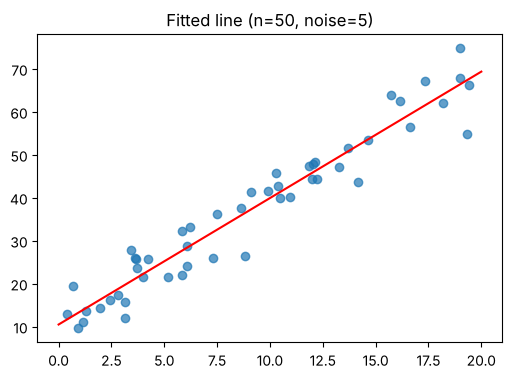

In [2]:
def make_data(n=50, noise=5.0, slope=3.0, intercept=10.0, seed=42):
    rng = np.random.RandomState(seed)
    x = rng.uniform(0, 20, n)
    y = intercept + slope * x + rng.normal(0, noise, n)
    return x.reshape(-1, 1), y

X, y = make_data()
# closed-form OLS
b1 = np.sum((X[:, 0] - X.mean()) * (y - y.mean())) / np.sum((X[:, 0] - X.mean()) ** 2)
b0 = y.mean() - b1 * X.mean()
model = LinearRegression().fit(X, y)
print(f'Closed form : intercept={b0:.3f}, slope={b1:.3f}')
print(f'scikit-learn: intercept={model.intercept_:.3f}, slope={model.coef_[0]:.3f}')
print(f'R2 = {r2_score(y, model.predict(X)):.3f}, MSE = {mean_squared_error(y, model.predict(X)):.2f}')

plt.scatter(X, y, alpha=.7); xx = np.linspace(0, 20, 100).reshape(-1, 1)
plt.plot(xx, model.predict(xx), 'r'); plt.title('Fitted line (n=50, noise=5)'); plt.show()

## Experiment: change the number of points, the noise and add an outlier

In [3]:
rows = []
for n in (10, 50, 500):
    for noise in (1, 5, 20):
        Xs, ys = make_data(n=n, noise=noise)
        m = LinearRegression().fit(Xs, ys)
        rows.append({'n_points': n, 'noise_sd': noise, 'slope': round(m.coef_[0], 3),
                     'intercept': round(m.intercept_, 3), 'R2': round(r2_score(ys, m.predict(Xs)), 3)})
pd.DataFrame(rows)

,n_points,noise_sd,slope,intercept,R2
0,10,1,3.075,8.664,0.999
1,10,5,3.377,3.318,0.976
2,10,20,4.509,-16.728,0.820
3,50,1,2.989,10.097,0.997
4,50,5,2.944,10.483,0.932
5,50,20,2.777,11.934,0.434
6,500,1,3.012,9.893,0.997
7,500,5,3.058,9.465,0.930
8,500,20,3.230,7.859,0.480


Without outlier: slope=2.944, R2=0.932
With outlier   : slope=2.268, R2=0.430


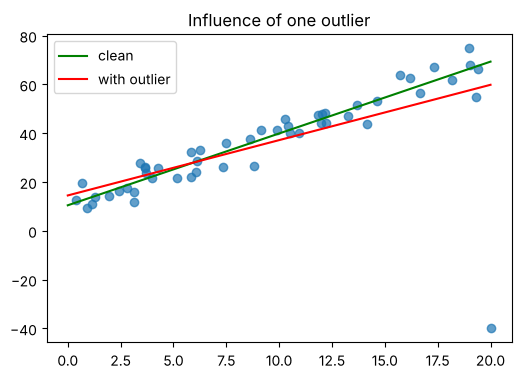

In [4]:
Xo, yo = make_data(n=50, noise=5)
Xo2 = np.vstack([Xo, [[20.0]]]); yo2 = np.append(yo, -40.0)      # one extreme point
m_clean = LinearRegression().fit(Xo, yo); m_out = LinearRegression().fit(Xo2, yo2)
print(f'Without outlier: slope={m_clean.coef_[0]:.3f}, R2={r2_score(yo, m_clean.predict(Xo)):.3f}')
print(f'With outlier   : slope={m_out.coef_[0]:.3f}, R2={r2_score(yo2, m_out.predict(Xo2)):.3f}')
plt.scatter(Xo2, yo2, alpha=.7)
plt.plot(xx, m_clean.predict(xx), 'g', label='clean'); plt.plot(xx, m_out.predict(xx), 'r', label='with outlier')
plt.legend(); plt.title('Influence of one outlier'); plt.show()

## Observations
* Closed-form OLS and scikit-learn agree exactly (intercept 10.483, slope 2.944), confirming the library implements least squares.
* The true slope is 3. With only 10 noisy points (sd 20) the estimated slope was 4.51 and the intercept -16.7; with 500 points it was 3.23. **More data stabilises the estimates**, but it does not remove noise, so R² stays near 0.43–0.48 when noise sd = 20.
* R² depends on noise, not sample size: it is ≈ 0.997 at noise 1 for n = 50 and n = 500 alike.
* One extreme point (20, -40) pulled the slope from 2.944 to 2.268 and dropped R² from 0.932 to 0.430 – least squares is highly sensitive to outliers because errors are squared.